In [71]:
import pandas as pd

Load the dataset and inspect it

In [72]:
reviews_dataset = pd.read_csv(r'/Users/varunkumarpyata/Downloads/Reviews.csv')


In [73]:
reviews_dataset.head(5)

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [74]:
reviews_dataset.shape

(568454, 10)

In [75]:
reviews_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   Id                      568454 non-null  int64 
 1   ProductId               568454 non-null  object
 2   UserId                  568454 non-null  object
 3   ProfileName             568428 non-null  object
 4   HelpfulnessNumerator    568454 non-null  int64 
 5   HelpfulnessDenominator  568454 non-null  int64 
 6   Score                   568454 non-null  int64 
 7   Time                    568454 non-null  int64 
 8   Summary                 568427 non-null  object
 9   Text                    568454 non-null  object
dtypes: int64(5), object(5)
memory usage: 43.4+ MB


In [76]:
reviews_dataset.columns.tolist()

['Id',
 'ProductId',
 'UserId',
 'ProfileName',
 'HelpfulnessNumerator',
 'HelpfulnessDenominator',
 'Score',
 'Time',
 'Summary',
 'Text']

choosing only score and text columns which are enough.Text is what the model will read. Score will help us create the sentiment labels 

In [77]:
reviews = pd.read_csv(r'/Users/varunkumarpyata/Downloads/Reviews.csv',usecols=['Score','Text'])

In [78]:
reviews.head(5)

,Score,Text
0,5,I have bought several of the Vitality canned d...
1,1,Product arrived labeled as Jumbo Salted Peanut...
2,4,This is a confection that has been around a fe...
3,2,If you are looking for the secret ingredient i...
4,5,Great taffy at a great price. There was a wid...


In [79]:
reviews.isna().sum()

Score    0
Text     0
dtype: int64

In [80]:
reviews["Score"].value_counts().sort_index()

Score
1     52268
2     29769
3     42640
4     80655
5    363122
Name: count, dtype: int64

Cleaning the review text

In [81]:
import re
import html
reviews = reviews.dropna(subset=["Text", "Score"])
reviews = reviews[reviews["Score"].isin([1, 2, 3, 4, 5])].copy()

def clean_text(text):
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = text.lower()
    text = re.sub(r"\s+", " ", text).strip()
    return text

reviews["clean_text"] = reviews["Text"].apply(clean_text)

reviews = reviews[reviews["clean_text"] != ""]
reviews = reviews.drop_duplicates(subset=["clean_text"]).copy()

reviews[["Text", "clean_text"]].head()

,Text,clean_text
0,I have bought several of the Vitality canned d...,i have bought several of the vitality canned d...
1,Product arrived labeled as Jumbo Salted Peanut...,product arrived labeled as jumbo salted peanut...
2,This is a confection that has been around a fe...,this is a confection that has been around a fe...
3,If you are looking for the secret ingredient i...,if you are looking for the secret ingredient i...
4,Great taffy at a great price. There was a wid...,great taffy at a great price. there was a wide...


Create the sentiment labels

In [82]:
rating_to_sentiment = {
    1: 0,
    2: 0,
    3: 1,
    4: 2,
    5: 2
}

reviews["sentiment"] = reviews["Score"].map(rating_to_sentiment)

reviews[["clean_text", "Score", "sentiment"]].head()

,clean_text,Score,sentiment
0,i have bought several of the vitality canned d...,5,2
1,product arrived labeled as jumbo salted peanut...,1,0
2,this is a confection that has been around a fe...,4,2
3,if you are looking for the secret ingredient i...,2,0
4,great taffy at a great price. there was a wide...,5,2


In [83]:
reviews[["clean_text", "Score", "sentiment"]].tail(5)

,clean_text,Score,sentiment
568449,great for sesame chicken..this is a good if no...,5,2
568450,i'm disappointed with the flavor. the chocolat...,2,0
568451,"these stars are small, so you can give 10-15 o...",5,2
568452,these are the best treats for training and rew...,5,2
568453,"i am very satisfied ,product is as advertised,...",5,2


Selecting 300 reviews from each class

In [84]:
samples = []

for label in [0, 1, 2]:
    class_reviews = reviews[reviews["sentiment"] == label]
    class_sample = class_reviews.sample(n=300, random_state=42)
    samples.append(class_sample)

nlp_sample = pd.concat(samples)

nlp_sample = nlp_sample.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

nlp_sample["sentiment"].value_counts().sort_index()

sentiment
0    300
1    300
2    300
Name: count, dtype: int64

In [85]:
X = nlp_sample["clean_text"]
y = nlp_sample["sentiment"]


spliting  our 900 reviews into training, validation and test sets.

In [86]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.4,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_test,
    y_test,
    test_size=0.5,
    random_state=42,
    stratify=y_test
)

In [87]:
pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Reviews": [len(X_train), len(X_val), len(X_test)]
})

,Dataset,Reviews
0,Training,540
1,Validation,180
2,Test,180


check the class balance in the training, validation, and test sets

In [88]:
pd.DataFrame({
    "Training": y_train.value_counts(),
    "Validation": y_val.value_counts(),
    "Test": y_test.value_counts()
}).sort_index()

,Training,Validation,Test
sentiment,,,
0,180,60,60
1,180,60,60
2,180,60,60


performing stemming

In [89]:
%pip install nltk

Note: you may need to restart the kernel to use updated packages.


In [90]:
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

def stem_text(text):
    words = re.findall(r"[a-z]+(?:'[a-z]+)?", text)
    stemmed_words = [stemmer.stem(word) for word in words]
    return " ".join(stemmed_words)

stem_text("the biscuits tasted delicious but were not fresh")

'the biscuit tast delici but were not fresh'

creating stemmed versions of our three sets:

In [91]:
X_train_stem = X_train.apply(stem_text)
X_val_stem = X_val.apply(stem_text)
X_test_stem = X_test.apply(stem_text)

pd.DataFrame({
    "Original cleaned text": X_train,
    "Stemmed text": X_train_stem
}).head()

,Original cleaned text,Stemmed text
195,"i mean earthy, like dirt. this tea is very woo...",i mean earthi like dirt thi tea is veri woodi ...
66,"this mix made tasty, crispy waffles using a st...",thi mix made tasti crispi waffl use a standard...
63,"the flavor, when mixed with water, is very wea...",the flavor when mix with water is veri weak pl...
661,i have never taken the time to write a review ...,i have never taken the time to write a review ...
134,i have tried both this and hawaii roasters bra...,i have tri both thi and hawaii roaster brand t...


Importing Lemmatization

In [92]:
#downloading the required language data
import nltk
from nltk.stem import WordNetLemmatizer
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')

[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/varunkumarpyata/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /Users/varunkumarpyata/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


True

In [93]:
import nltk
from pathlib import Path

nltk.download(
    "averaged_perceptron_tagger_eng",
    download_dir=str(Path.home() / "nltk_data"),
    raise_on_error=True
)

nltk.pos_tag(["the", "biscuits", "tasted", "delicious"])

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /Users/varunkumarpyata/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


[('the', 'DT'), ('biscuits', 'NNS'), ('tasted', 'VBD'), ('delicious', 'JJ')]

In [94]:
#creating a lemmatizer function
lemmatizer = WordNetLemmatizer()

pos_map = {
    "J": "a",
    "V": "v",
    "N": "n",
    "R": "r"
}

def lemmatize_text(text):
    words = re.findall(r"[a-z]+(?:'[a-z]+)?", text)
    tagged_words = nltk.pos_tag(words)

    lemmatized_words = []

    for word, tag in tagged_words:
        wordnet_pos = pos_map.get(tag[0], "n")
        lemma = lemmatizer.lemmatize(word, pos=wordnet_pos)
        lemmatized_words.append(lemma)

    return " ".join(lemmatized_words)

lemmatize_text("the biscuits tasted delicious but were not fresh")

'the biscuit taste delicious but be not fresh'

In [95]:
#comparing all three text versions
X_train_lemma = X_train.apply(lemmatize_text)
X_val_lemma = X_val.apply(lemmatize_text)
X_test_lemma = X_test.apply(lemmatize_text) 

pd.DataFrame({"cleaned": X_train, "stemmed": X_train_stem, "lemmatized": X_train_lemma}).head()

,cleaned,stemmed,lemmatized
195,"i mean earthy, like dirt. this tea is very woo...",i mean earthi like dirt thi tea is veri woodi ...,i mean earthy like dirt this tea be very woody...
66,"this mix made tasty, crispy waffles using a st...",thi mix made tasti crispi waffl use a standard...,this mix make tasty crispy waffle use a standa...
63,"the flavor, when mixed with water, is very wea...",the flavor when mix with water is veri weak pl...,the flavor when mixed with water be very weak ...
661,i have never taken the time to write a review ...,i have never taken the time to write a review ...,i have never take the time to write a review b...
134,i have tried both this and hawaii roasters bra...,i have tri both thi and hawaii roaster brand t...,i have try both this and hawaii roaster brand ...


In [96]:
#creating a TF-IDF vectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    stop_words=None,
    token_pattern=r"[a-z]+(?:'[a-z]+)?"
)

In [97]:
#converting the three sets of text into TF-IDF features
X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

In [98]:
#now checking the shape of the three sets of TF-IDF features
pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Reviews": [
        X_train_tfidf.shape[0],
        X_val_tfidf.shape[0],
        X_test_tfidf.shape[0]
    ],
    "Features": [
        X_train_tfidf.shape[1],
        X_val_tfidf.shape[1],
        X_test_tfidf.shape[1]
    ]
})

,Dataset,Reviews,Features
0,Training,540,5000
1,Validation,180,5000
2,Test,180,5000


In [99]:
#inspecting the first 20 features of the TF-IDF vectorizer
pd.DataFrame({
    "Feature": tfidf.get_feature_names_out()[:20],
    "TF-IDF Score": tfidf.idf_[:20]
})

,Feature,TF-IDF Score
0,a,1.282152
1,a bad,5.347509
2,a bag,5.501660
3,a batch,5.501660
4,a beagle,6.194807
5,a best,5.907125
6,a better,5.683981
7,a big,4.654362
8,a bigger,5.907125
9,a bit,3.555750


In [41]:
tfidf.get_feature_names_out()[:20]

array(['a', 'a bad', 'a bag', 'a batch', 'a beagle', 'a best', 'a better',
       'a big', 'a bigger', 'a bit', 'a bite', 'a bitter', 'a bottle',
       'a bowl', 'a box', 'a can', 'a case', 'a cat', 'a cereal',
       'a chance'], dtype=object)

Train the model using logistic regression

In [100]:
#Train the model using the cleaned-text features
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

lr_clean = LogisticRegression(max_iter=1000)

lr_clean.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000)

In [101]:
#Predicting validation labels and checking the performance
y_val_pred_clean = lr_clean.predict(X_val_tfidf)

clean_results = pd.DataFrame({
    "Model": ["Logistic Regression"],
    "Text version": ["Cleaned"],
    "Validation accuracy": [
        accuracy_score(y_val, y_val_pred_clean)
    ],
    "Validation macro F1": [
        f1_score(y_val, y_val_pred_clean, average="macro")
    ]
})

clean_results

,Model,Text version,Validation accuracy,Validation macro F1
0,Logistic Regression,Cleaned,0.605556,0.604377


In [102]:
#now Checking the performance for each class
report = classification_report(
    y_val, 
    y_val_pred_clean,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    output_dict=True,
    zero_division=0
)

In [106]:
print(report)

{'Negative': {'precision': 0.6, 'recall': 0.65, 'f1-score': 0.624, 'support': 60.0}, 'Neutral': {'precision': 0.5636363636363636, 'recall': 0.5166666666666667, 'f1-score': 0.5391304347826087, 'support': 60.0}, 'Positive': {'precision': 0.65, 'recall': 0.65, 'f1-score': 0.65, 'support': 60.0}, 'accuracy': 0.6055555555555555, 'macro avg': {'precision': 0.6045454545454545, 'recall': 0.6055555555555556, 'f1-score': 0.6043768115942029, 'support': 180.0}, 'weighted avg': {'precision': 0.6045454545454545, 'recall': 0.6055555555555555, 'f1-score': 0.604376811594203, 'support': 180.0}}


In [108]:
class_report = classification_report(
    y_val,
    y_val_pred_clean,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    output_dict=True,
    zero_division=0
)

pd.DataFrame(class_report).T.loc[
    ["Negative", "Neutral", "Positive", "macro avg", "weighted avg"]
].round(3)

,precision,recall,f1-score,support
Negative,0.600,0.650,0.624,60.0
Neutral,0.564,0.517,0.539,60.0
Positive,0.650,0.650,0.650,60.0
macro avg,0.605,0.606,0.604,180.0
weighted avg,0.605,0.606,0.604,180.0


comparing stemming and lemmatization using the same model and TF-IDF settings.

In [109]:
#Train the stemming version
from sklearn.base import clone

tfidf_stem = clone(tfidf)

X_train_stem_tfidf = tfidf_stem.fit_transform(X_train_stem)
X_val_stem_tfidf = tfidf_stem.transform(X_val_stem)

lr_stem = LogisticRegression(max_iter=1000)
lr_stem.fit(X_train_stem_tfidf, y_train)

y_val_pred_stem = lr_stem.predict(X_val_stem_tfidf)

In [111]:
#Train the lemmatized version
tfidf_lemma = clone(tfidf)

X_train_lemma_tfidf = tfidf_lemma.fit_transform(X_train_lemma)
X_val_lemma_tfidf = tfidf_lemma.transform(X_val_lemma)

lr_lemma = LogisticRegression(max_iter=1000)
lr_lemma.fit(X_train_lemma_tfidf, y_train)

y_val_pred_lemma = lr_lemma.predict(X_val_lemma_tfidf)

In [113]:
#displaying the performance of all three text versions
def score_row(text_version, predictions):
    return {
        "Text version": text_version,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions,
            average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions,
            average="macro", zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions,
            average="macro", zero_division=0
        )
    }

preprocessing_scores = pd.DataFrame([
    score_row("Cleaned", y_val_pred_clean),
    score_row("Stemmed", y_val_pred_stem),
    score_row("Lemmatized", y_val_pred_lemma)
])

preprocessing_scores.sort_values(
    "F1", ascending=False
).round(3)

,Text version,Accuracy,Precision,Recall,F1
0,Cleaned,0.606,0.605,0.606,0.604
2,Lemmatized,0.594,0.593,0.594,0.593
1,Stemmed,0.572,0.571,0.572,0.571


Now training with naive bayes model and LinearSVM model to check the performance of all three text versions 

In [114]:
#Train Naive Bayes
from sklearn.naive_bayes import MultinomialNB

nb_clean = MultinomialNB()

nb_clean.fit(X_train_tfidf, y_train)

y_val_pred_nb = nb_clean.predict(X_val_tfidf)

In [115]:
#Train Linear SVM
from sklearn.svm import LinearSVC

svm_clean = LinearSVC(
    max_iter=5000,
    random_state=42
)

svm_clean.fit(X_train_tfidf, y_train)

y_val_pred_svm = svm_clean.predict(X_val_tfidf)

In [117]:
from sklearn.base import clone

feature_sets = {
    "Cleaned": (X_train_tfidf, X_val_tfidf),
    "Stemmed": (X_train_stem_tfidf, X_val_stem_tfidf),
    "Lemmatized": (X_train_lemma_tfidf, X_val_lemma_tfidf)
}

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(max_iter=5000, random_state=42)
}

results = []
trained_models = {}

for text_version, (train_features, val_features) in feature_sets.items():

    for model_name, model_template in models.items():
        model = clone(model_template)

        model.fit(train_features, y_train)
        predictions = model.predict(val_features)

        row = score_row(text_version, predictions)
        row["Model"] = model_name
        results.append(row)

        trained_models[(text_version, model_name)] = model

all_scores = pd.DataFrame(results)

all_scores = all_scores[
    ["Model", "Text version", "Accuracy", "Precision", "Recall", "F1"]
]

all_scores.sort_values(
    "F1", ascending=False
).reset_index(drop=True).round(3)

,Model,Text version,Accuracy,Precision,Recall,F1
0,Linear SVM,Cleaned,0.617,0.617,0.617,0.615
1,Linear SVM,Stemmed,0.611,0.610,0.611,0.611
2,Naive Bayes,Cleaned,0.606,0.624,0.606,0.606
3,Logistic Regression,Cleaned,0.606,0.605,0.606,0.604
4,Logistic Regression,Lemmatized,0.594,0.593,0.594,0.593
5,Linear SVM,Lemmatized,0.578,0.576,0.578,0.576
6,Logistic Regression,Stemmed,0.572,0.571,0.572,0.571
7,Naive Bayes,Stemmed,0.561,0.577,0.561,0.560
8,Naive Bayes,Lemmatized,0.522,0.538,0.522,0.525


In [ ]:
#Compare all three models with only cleaned text features
model_scores = pd.DataFrame([
    score_row("Cleaned", y_val_pred_clean),
    score_row("Cleaned", y_val_pred_nb),
    score_row("Cleaned", y_val_pred_svm)
])

model_scores.insert(
    0,
    "Model",
    ["Logistic Regression", "Naive Bayes", "Linear SVM"]
)

model_scores.sort_values(
    "F1", ascending=False
).round(3)

,Model,Text version,Accuracy,Precision,Recall,F1
2,Linear SVM,Cleaned,0.617,0.617,0.617,0.615
1,Naive Bayes,Cleaned,0.606,0.624,0.606,0.606
0,Logistic Regression,Cleaned,0.606,0.605,0.606,0.604


Evaluating the selected model on our 180 test reviews.

The model comparisons and final evaluation

In [118]:
#Get the model and calculate test scores
best_model = trained_models[("Cleaned", "Linear SVM")]
best_vectorizer = tfidf

y_test_pred = best_model.predict(X_test_tfidf)

test_scores = pd.DataFrame({
    "Model": ["Linear SVM"],
    "Text version": ["Cleaned"],
    "Accuracy": [
        accuracy_score(y_test, y_test_pred)
    ],
    "Precision": [
        precision_score(
            y_test, y_test_pred,
            average="macro", zero_division=0
        )
    ],
    "Recall": [
        recall_score(
            y_test, y_test_pred,
            average="macro", zero_division=0
        )
    ],
    "F1": [
        f1_score(
            y_test, y_test_pred,
            average="macro", zero_division=0
        )
    ]
})

test_scores.round(3)

,Model,Text version,Accuracy,Precision,Recall,F1
0,Linear SVM,Cleaned,0.6,0.596,0.6,0.596


In [120]:
#now checking all the classes for the test set
test_report = classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    output_dict=True,
    zero_division=0
)

pd.DataFrame(test_report).T.loc[
    ["Negative", "Neutral", "Positive", "macro avg", "weighted avg"]
].round(3)

,precision,recall,f1-score,support
Negative,0.559,0.55,0.555,60.0
Neutral,0.566,0.50,0.531,60.0
Positive,0.662,0.75,0.703,60.0
macro avg,0.596,0.60,0.596,180.0
weighted avg,0.596,0.60,0.596,180.0


In [121]:
#displaying the confusion matrix for the test set
from sklearn.metrics import confusion_matrix

class_names = ["Negative", "Neutral", "Positive"]

test_confusion_matrix = pd.DataFrame(
    confusion_matrix(y_test, y_test_pred, labels=[0, 1, 2]),
    index=class_names,
    columns=class_names
)

test_confusion_matrix.index.name = "Actual"
test_confusion_matrix.columns.name = "Predicted"

test_confusion_matrix

Predicted,Negative,Neutral,Positive
Actual,,,
Negative,33,13,14
Neutral,21,30,9
Positive,5,10,45


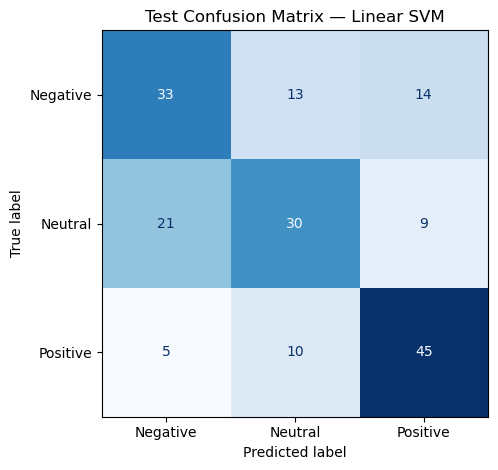

In [122]:
#plotting the confusion matrix for the test set
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    labels=[0, 1, 2],
    display_labels=["Negative", "Neutral", "Positive"],
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Test Confusion Matrix — Linear SVM")
plt.tight_layout()
plt.show()

saving the best model and vectorizer for future use 

In [124]:
import joblib

sentiment_bundle = {
    "model": best_model,
    "vectorizer": best_vectorizer,
    "labels": {
        0: "Negative",
        1: "Neutral",
        2: "Positive"
    }
}

joblib.dump(sentiment_bundle, "sentiment_model.joblib")

['sentiment_model.joblib']

In [125]:
#checking wether the above file saved or not and the loctaion of the file
from pathlib import Path

Path("sentiment_model.joblib").resolve()

PosixPath('/Users/varunkumarpyata/Downloads/sentiment_NLP.ipynb/sentiment_model.joblib')

In [126]:
from pathlib import Path

model_path = Path("sentiment_model.joblib")

{
    "File saved": model_path.is_file(),
    "File location": str(model_path.resolve())
}

{'File saved': True,
 'File location': '/Users/varunkumarpyata/Downloads/sentiment_NLP.ipynb/sentiment_model.joblib'}